# Projet de Détection de Fake News
Ce carnet permet d'analyser et de modéliser votre dataset de 69 000 lignes contenant 3 colonnes : `SNO` (identifiant), `newa` (le texte) et la 3ème colonne (Vrai=1, Faux=0).

Les étapes abordées sont :
1. Importation et Analyse Exploratoire des Données (EDA)
2. Prétraitement du texte et Vectorisation (TF-IDF)
3. Entraînement d'un modèle de Machine Learning
4. Évaluation des performances

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
import re

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve, StratifiedKFold, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

## 1. Chargement des données et Analyse (EDA)

Aperçu des données originales :


,SNO,News,Label
0,35098,(Welcome) to America We hope you enjoy our...,0
1,37968,(Welcome) to America We hope you enjoy our...,0
2,66775,Kendall Kylie Jenner Jenner NOT Upset Up...,0
3,65622,Kim Kardashian Dethroned Dethroned By Khlo...,0
4,68069,Kim Kardashian Did NOT Hot Staffer Hot Sta...,0


--- FUSION TERMINÉE ---
Taille de l'ancien dataset : 69031 lignes
Taille ajoutée (Fake) : 23481 lignes
Taille ajoutée (True) : 21417 lignes
Taille du NOUVEAU dataset global : 113929 lignes

Nouvelle distribution des labels :
Label
1    61821
0    52108
Name: count, dtype: int64

Dimension du dataset APRÈS nettoyage : 106733 lignes et 5 colonnes.

--- DISTRIBUTION DES LABELS ---
Label
1    60468
0    46265
Name: count, dtype: int64


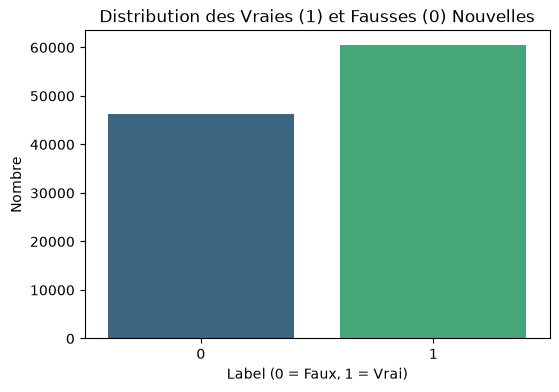

In [4]:
# Chargement du dataset avec gestion des erreurs de formatage (C error: Expected X fields)
df = pd.read_excel('Train.xlsx')
df.columns = ['SNO', 'News', 'Label']

print("Aperçu des données originales :")
display(df.head())



# 1. Charger les nouveaux fichiers (ajustez l'encodage 'utf-8' ou 'latin-1' si besoin)
df_fake = pd.read_csv('Fake.csv', on_bad_lines='skip')
df_true = pd.read_csv('True.csv', on_bad_lines='skip')

# 2. Renommer l'unique colonne de texte pour qu'elle corresponde au dataset principal ('News')
df_fake.rename(columns={df_fake.columns[0]: 'News'}, inplace=True)
df_true.rename(columns={df_true.columns[0]: 'News'}, inplace=True)

# 3. Assigner les bons labels
df_fake['Label'] = 0  # 0 pour Fake
df_true['Label'] = 1  # 1 pour True

# 4. Fusionner l'ancien dataset (df) avec les deux nouveaux
df_combined = pd.concat([df, df_fake, df_true], ignore_index=True)

# 5. Mélanger aléatoirement le nouveau dataset complet 
# (Obligatoire, sinon tous les fakes et trues seront regroupés)
df_combined = df_combined.sample(frac=1, random_state=42).reset_index(drop=True)

# Affichage des résultats
print("--- FUSION TERMINÉE ---")
print(f"Taille de l'ancien dataset : {len(df)} lignes")
print(f"Taille ajoutée (Fake) : {len(df_fake)} lignes")
print(f"Taille ajoutée (True) : {len(df_true)} lignes")
print(f"Taille du NOUVEAU dataset global : {len(df_combined)} lignes")

# Afficher la nouvelle distribution pour s'assurer que les classes sont équilibrées
print("\nNouvelle distribution des labels :")
print(df_combined['Label'].value_counts())

# Optionnel : Remplacer l'ancien df par le nouveau pour la suite de votre code
df = df_combined

# Nettoyage
df = df.drop(columns=['SNO'], errors='ignore')
df = df.dropna(subset=['News', 'Label'])

# B. Suppression des lignes avec des valeurs manquantes dans les textes ou les labels
df = df.dropna(subset=['News', 'Label'])

# C. Suppression des doublons exacts pour ne pas biaiser le modèle
df = df.drop_duplicates()

print(f"\nDimension du dataset APRÈS nettoyage : {df.shape[0]} lignes et {df.shape[1]} colonnes.")
# 4. VÉRIFICATION DE L'ÉQUILIBRE DES CLASSES
# ==========================================
print("\n--- DISTRIBUTION DES LABELS ---")
print(df['Label'].value_counts())

# Affichage de la distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Label', data=df, palette='viridis')
plt.title('Distribution des Vraies (1) et Fausses (0) Nouvelles')
plt.xlabel('Label (0 = Faux, 1 = Vrai)')
plt.ylabel('Nombre')
plt.show()

In [5]:


def nettoyer_texte(texte):
    if not isinstance(texte, str):
        return ""
    # Remplacer les caractères bizarres et la ponctuation par un espace
    texte = re.sub(r'[^\w\s]', ' ', texte)
    # Supprimer les mots contenant des caractères non-ASCII (comme les œ ou â)
    texte = re.sub(r'[^\x00-\x7F]+', ' ', texte)
    # Remplacer les espaces multiples par un seul espace
    texte = re.sub(r'\s+', ' ', texte).strip()
    return texte

# Appliquer le nettoyage avant de définir X et y
df['News_Clean'] = df['News'].apply(nettoyer_texte)
X = df['News_Clean']

## 2. Prétraitement et Vectorisation du Texte
L'algorithme a besoin de données numériques. Nous allons utiliser **TF-IDF** pour transformer le texte en vecteurs mathématiques.

In [6]:
# 1. DONNÉES (plus de séparation train/test)
X = df['News']
y = df['Label']

# 2. PIPELINE : vectorisation + modèle
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=10000, lowercase=True)),
    ('clf', LogisticRegression(max_iter=1000))
])

# 3. GRILLE DE PARAMÈTRES (préfixe "clf__" = étape du pipeline)
parametres_a_tester = {
    'clf__C': [0.1, 1, 10, 100],
    'clf__solver': ['liblinear', 'lbfgs']
}

# 4. VALIDATION CROISÉE IMBRIQUÉE (nested CV)
# Boucle interne : choix des meilleurs hyperparamètres
cv_interne = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
chercheur = GridSearchCV(pipeline, parametres_a_tester,
                         cv=cv_interne, scoring='accuracy', n_jobs=-1)

# Boucle externe : évaluation honnête, chaque exemple est prédit
# par un modèle qui ne l'a jamais vu
cv_externe = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred = cross_val_predict(chercheur, X, y, cv=cv_externe)

print("--- PERFORMANCES (validation croisée imbriquée) ---")
print(classification_report(y, y_pred))

# 5. MODÈLE FINAL : recherche des meilleurs paramètres sur TOUTES les données
chercheur.fit(X, y)
best_model = chercheur.best_estimator_

print("\n--- RÉSULTATS DE L'OPTIMISATION ---")
print(f"Meilleurs paramètres : {chercheur.best_params_}")
print(f"Précision moyenne (CV interne) : {chercheur.best_score_:.2%}")

--- PERFORMANCES (validation croisée imbriquée) ---
              precision    recall  f1-score   support

           0       0.92      0.90      0.91     46265
           1       0.92      0.94      0.93     60468

    accuracy                           0.92    106733
   macro avg       0.92      0.92      0.92    106733
weighted avg       0.92      0.92      0.92    106733


--- RÉSULTATS DE L'OPTIMISATION ---
Meilleurs paramètres : {'clf__C': 10, 'clf__solver': 'liblinear'}
Précision moyenne (CV interne) : 92.23%


Calcul de la courbe d'apprentissage en cours...


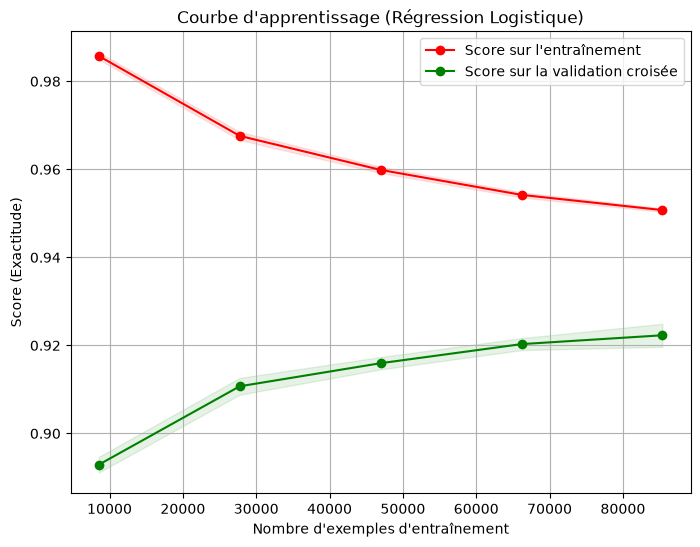

In [7]:
print("Calcul de la courbe d'apprentissage en cours...")

# best_model est le Pipeline entraîné par GridSearchCV (TF-IDF + LogisticRegression)
modele_a_evaluer = best_model

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# On passe le texte brut (X) et non plus X_train_vec : le pipeline vectorise lui-même
train_sizes, train_scores, test_scores = learning_curve(
    estimator=modele_a_evaluer,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Moyennes et écarts-types
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

# --- TRACÉ DU GRAPHIQUE ---
plt.figure(figsize=(8, 6))
plt.title("Courbe d'apprentissage (Régression Logistique)")
plt.xlabel("Nombre d'exemples d'entraînement")
plt.ylabel("Score (Exactitude)")
plt.grid(True)

plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1, color="g")

plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Score sur l'entraînement")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Score sur la validation croisée")

plt.legend(loc="best")
plt.show()

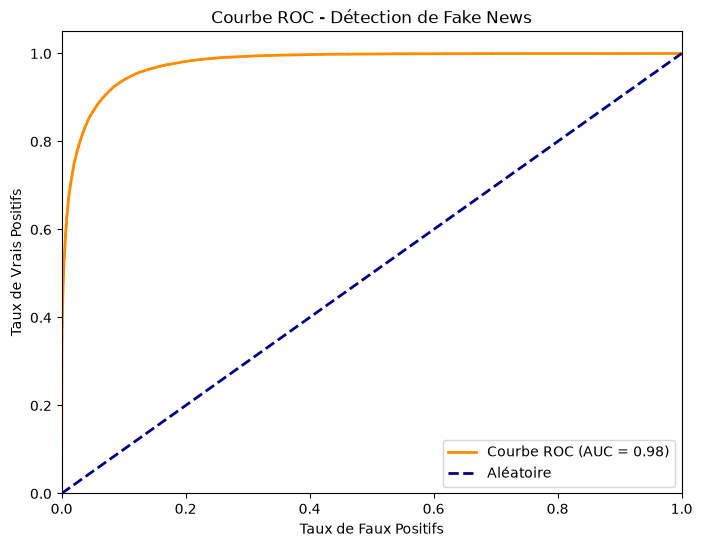

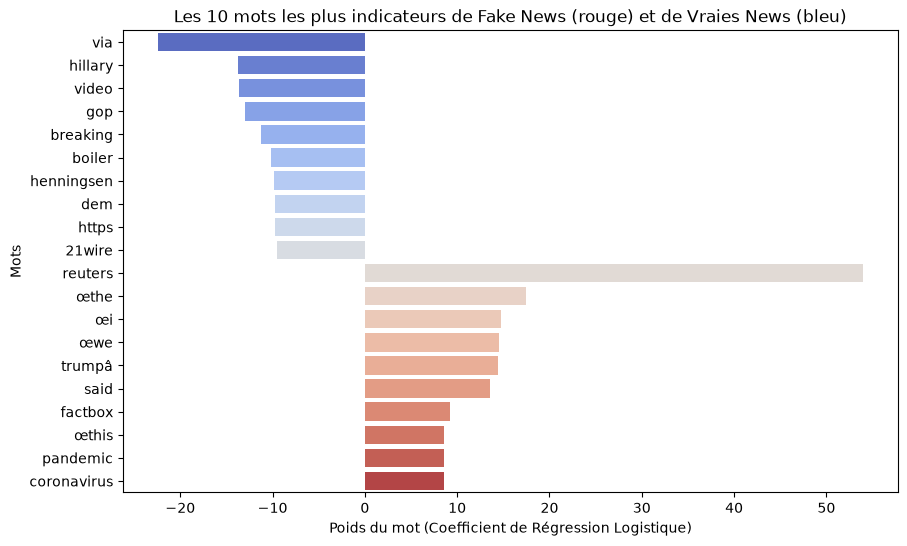

In [8]:
# ==========================================
# GRAPH 1: ROC CURVE
# ==========================================
# Out-of-fold probabilities: each example is scored by a model that never saw it.
# `chercheur` (the GridSearchCV) is used so the hyperparameter choice is also kept out of the evaluation.
cv_externe = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_prob = cross_val_predict(chercheur, X, y, cv=cv_externe,
                           method='predict_proba', n_jobs=-1)[:, 1]

fpr, tpr, thresholds = roc_curve(y, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Courbe ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aléatoire')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs')
plt.ylabel('Taux de Vrais Positifs')
plt.title('Courbe ROC - Détection de Fake News')
plt.legend(loc="lower right")
plt.show()

# ==========================================
# GRAPH 2: WORD IMPORTANCE (TOP 10 / BOTTOM 10)
# ==========================================
# Retrieve the steps from inside the pipeline
vectorizer = best_model.named_steps['tfidf']
clf = best_model.named_steps['clf']

mots = vectorizer.get_feature_names_out()
coefficients = clf.coef_[0]

df_coef = pd.DataFrame({'Mot': mots, 'Coefficient': coefficients})

top_vrais = df_coef.sort_values(by='Coefficient', ascending=False).head(10)
top_faux = df_coef.sort_values(by='Coefficient', ascending=True).head(10)
top_mots = pd.concat([top_faux, top_vrais])

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Mot', data=top_mots,
            hue='Mot', palette="coolwarm", legend=False)
plt.title('Les 10 mots les plus indicateurs de Fake News (rouge) et de Vraies News (bleu)')
plt.xlabel('Poids du mot (Coefficient de Régression Logistique)')
plt.ylabel('Mots')
plt.show()

## 3. Entraînement et Évaluation du Modèle (Régression Logistique)

--- Rapport de Classification ---
              precision    recall  f1-score   support

           0       0.92      0.90      0.91     46265
           1       0.92      0.94      0.93     60468

    accuracy                           0.92    106733
   macro avg       0.92      0.92      0.92    106733
weighted avg       0.92      0.92      0.92    106733



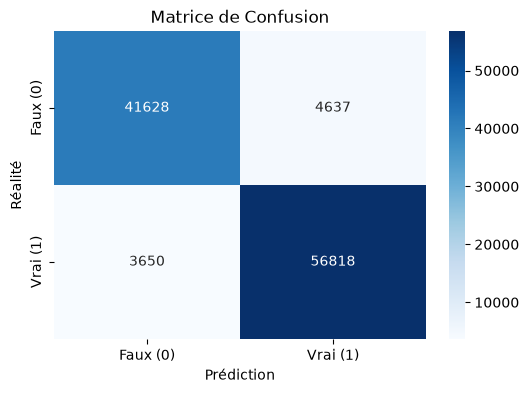

In [9]:
# Prédictions out-of-fold : chaque exemple est prédit par un modèle qui ne l'a jamais vu
cv_externe = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_pred = cross_val_predict(chercheur, X, y, cv=cv_externe, n_jobs=-1)

print("--- Rapport de Classification ---")
print(classification_report(y, y_pred))

cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Faux (0)', 'Vrai (1)'],
            yticklabels=['Faux (0)', 'Vrai (1)'])
plt.title('Matrice de Confusion')
plt.xlabel('Prédiction')
plt.ylabel('Réalité')
plt.show()

In [10]:
# 1. Création des éléments de l'interface
titre = widgets.HTML("<h3>Testeur de Fake News Interactif</h3>")

texte_input = widgets.Textarea(
    value='',
    placeholder='Collez un article ou une phrase ici pour tester...',
    description='Nouvelle :',
    layout=widgets.Layout(width='80%', height='100px')
)

bouton_tester = widgets.Button(
    description='Lancer la détection',
    button_style='primary',
    icon='search'
)

sortie_resultat = widgets.Output()

# 2. Fonction de prédiction liée au bouton
def tester_texte(b):
    with sortie_resultat:
        sortie_resultat.clear_output()
        nouveau_texte = texte_input.value

        if not nouveau_texte.strip():
            print("⚠️ Veuillez entrer du texte avant de tester.")
            return

        # Le pipeline vectorise (TF-IDF) puis prédit : on lui passe le texte brut
        prediction = best_model.predict([nouveau_texte])[0]

        # Probabilité associée à la classe prédite (niveau de confiance)
        probas = best_model.predict_proba([nouveau_texte])[0]
        confiance = probas.max()

        print("-" * 50)
        if prediction == 1:
            print(f"🟢 VERDICT : Ceci semble être une VRAIE nouvelle. (confiance : {confiance:.1%})")
        else:
            print(f"🔴 VERDICT : Ceci semble être une FAUSSE nouvelle (Fake News). (confiance : {confiance:.1%})")
        print("-" * 50)

# 3. Connecter le clic du bouton à la fonction
bouton_tester.on_click(tester_texte)

# 4. Afficher l'interface
display(titre, texte_input, bouton_tester, sortie_resultat)

HTML(value='<h3>Testeur de Fake News Interactif</h3>')

Textarea(value='', description='Nouvelle :', layout=Layout(height='100px', width='80%'), placeholder='Collez u…

Button(button_style='primary', description='Lancer la détection', icon='search', style=ButtonStyle())

Output()